# 01. Simulación y validación de los datos

Recreación con datos simulados de Imtiaz et al. (2025), *Computers and Electronics in Agriculture*, 237, 110636.

Este notebook genera la base simulada y la valida con análisis univariado y multivariado, comparándola con lo reportado en el artículo.

## 1. Configuración

Se importan las librerías y los módulos del proyecto. Como el notebook está en la carpeta `notebooks/`, se agrega la carpeta raíz del proyecto a la ruta de búsqueda de Python para poder importar el paquete `src`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Carpeta raíz del proyecto (un nivel arriba de notebooks/)
RAIZ = Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import config
from src.simulacion import generar_base

sns.set_theme(style="whitegrid", context="notebook")
print("Raíz del proyecto:", RAIZ)
print("Semilla:", config.SEMILLA)
print("Ruido calibrado:", config.RUIDO)

Raíz del proyecto: c:\Users\isabe\Cursos\proyecto_ml_final
Semilla: 42
Ruido calibrado: {'desacople': 0.35, 'sensor': {'Sentinel-2': 0.02, 'PlanetScope': 0.025}, 'iluminacion': 0.03}


**Resultado.** El entorno quedó configurado: se reconoce la raíz del proyecto, la semilla base (42) y el ruido calibrado con las parcelas A y C (desacople de 0,35; ruido del sensor de 2,0 % en Sentinel-2 y 2,5 % en PlanetScope).

## 2. Generación y carga de la base

La base se genera con `generar_base()` usando la semilla del proyecto (`config.SEMILLA = 42`) y se guarda en `data/datos_simulados.csv`. Luego se lee el archivo guardado y se compara con la base generada, para comprobar que el CSV publicado en el repositorio puede reproducirse exactamente a partir del código.

Diseño de la base:

- **Parcelas A y C** (cosechadora): 300 puntos de muestreo.
- **Parcelas B y D** (excavación manual): 300 puntos de muestreo y 30 puntos de medición.
- Cada punto aparece **4 veces**: 2 sensores (Sentinel-2 y PlanetScope) × 2 estrategias de simulación (univariada y multivariada).

In [2]:
# Generar la base desde cero y guardarla en data/
base = generar_base()

# Volver a leer el archivo guardado
copia = pd.read_csv(config.DIR_DATOS / "datos_simulados.csv")

# Comparar las columnas numéricas (los vacíos se reemplazan por -1 solo para comparar)
columnas_numericas = base.select_dtypes("number").columns
identicas = np.allclose(
    base[columnas_numericas].fillna(-1).to_numpy(),
    copia[columnas_numericas].fillna(-1).to_numpy(),
)

print("Dimensiones:", base.shape)
print("¿La base guardada es idéntica a la generada?", identicas)

# Número de puntos distintos por parcela y tipo (cada punto aparece 4 veces)
puntos = (base.groupby(["parcela", "metodo", "tipo_punto"]).size()
          .div(4).astype(int).rename("puntos").reset_index())
puntos

Dimensiones: (5040, 21)
¿La base guardada es idéntica a la generada? True


,parcela,metodo,tipo_punto,puntos
0,A,cosechadora,muestreo,300
1,B,excavacion,medicion,30
2,B,excavacion,muestreo,300
3,C,cosechadora,muestreo,300
4,D,excavacion,medicion,30
5,D,excavacion,muestreo,300


**Resultado.** La base tiene 5.040 filas y 21 columnas, y es idéntica al archivo guardado: los datos publicados se reproducen exactamente con el código y la semilla.

| Parcela | Método | Puntos de muestreo | Puntos de medición |
|---|---|---|---|
| A | Cosechadora | 300 | — |
| B | Excavación | 300 | 30 |
| C | Cosechadora | 300 | — |
| D | Excavación | 300 | 30 |

Los 300 puntos de muestreo por parcela reproducen el diseño del artículo. Los 30 puntos de medición de B y D corresponden a la excavación manual (3 zonas × 10 puntos) y se usarán para analizar la fuga de información por interpolación.

## 3. Estructura de la base

Cada columna cumple un rol distinto en el análisis:

- **Diseño:** identifican la combinación experimental (parcela, sensor, estrategia, tipo de punto) y no se usan como predictores.
- **Ubicación:** coordenadas `x`, `y` en metros, necesarias para el análisis espacial de la fuga de información.
- **Respuesta:** `rendimiento` (t/ha), el rendimiento real de cada punto. En B y D existe además `rendimiento_interpolado`, la versión que usó el artículo.
- **Predictores:** las 4 bandas y los 4 índices de vegetación (8 en total).
- **Diagnóstico:** `cobertura_real` solo sirve para explicar el generador; usarla como predictor sería una fuga de información, porque en la realidad no se observa.

Como referencia para el resumen estadístico se toma Sentinel-2 con la estrategia multivariada y solo los puntos de muestreo, que es la combinación más cercana al análisis del artículo.

In [3]:
# Rol de cada columna
roles = {
    "semilla": "diseño", "parcela": "diseño", "anio": "diseño", "metodo": "diseño",
    "sensor": "diseño", "estrategia": "diseño", "tipo_punto": "diseño", "punto": "diseño",
    "x": "ubicación", "y": "ubicación",
    "rendimiento": "respuesta (real)",
    "rendimiento_interpolado": "respuesta (artículo, B y D)",
    "cobertura_real": "diagnóstico (no predictor)",
}
roles.update({b: "predictor (banda)" for b in config.BANDAS})
roles.update({i: "predictor (índice)" for i in config.INDICES})

estructura = pd.DataFrame({
    "columna": base.columns,
    "tipo": base.dtypes.astype(str).values,
    "rol": [roles[c] for c in base.columns],
    "vacíos": base.isna().sum().values,
})
display(estructura)

# Resumen de la respuesta y los predictores (combinación de referencia)
referencia = base[
    (base["sensor"] == "Sentinel-2")
    & (base["estrategia"] == "multivariada")
    & (base["tipo_punto"] == "muestreo")
]
resumen = (referencia[[config.VARIABLE_RESPUESTA] + config.PREDICTORES]
           .describe().T[["mean", "std", "min", "max"]].round(3))
display(resumen)

,columna,tipo,rol,vacíos
0,semilla,int64,diseño,0
1,parcela,str,diseño,0
2,anio,int64,diseño,0
3,metodo,str,diseño,0
4,sensor,str,diseño,0
5,estrategia,str,diseño,0
6,tipo_punto,str,diseño,0
7,punto,int64,diseño,0
8,x,float64,ubicación,0
9,y,float64,ubicación,0


,mean,std,min,max
rendimiento,67.863,23.032,26.022,110.000
azul,0.035,0.009,0.023,0.058
verde,0.074,0.009,0.058,0.100
rojo,0.069,0.023,0.038,0.124
nir,0.389,0.039,0.288,0.469
ndvi,0.695,0.108,0.447,0.840
gndvi,0.678,0.055,0.544,0.753
evi,0.521,0.106,0.289,0.694
savi,0.500,0.085,0.303,0.629


**Resultado.**

*Estructura.* La base tiene 21 columnas: 8 de diseño, 2 de ubicación, 2 versiones de la respuesta, 8 predictores y 1 de diagnóstico. La única columna con vacíos es `rendimiento_interpolado` (2.400 vacíos), que solo existe en las parcelas de excavación (B y D); en A y C no hubo interpolación desde 30 puntos.

*Respuesta.* Con las cuatro parcelas juntas, el rendimiento va de 26 a 110 t/ha, con media de 67,9 y desviación estándar de 23,0 t/ha. Esta desviación es mucho mayor que la de cada parcela por separado (entre 5 y 10 t/ha): la mayor parte de la variabilidad total se debe a la diferencia entre parcelas de rendimiento bajo (A y C, ~46 t/ha) y alto (B y D, ~90 t/ha). Es la base cuantitativa del hallazgo 2: una correlación calculada con las cuatro parcelas juntas se infla por esta diferencia.

*Predictores.* Las reflectancias están en rangos típicos de un dosel de papa en un compuesto de temporada: rojo bajo (0,04–0,12) y NIR alto (0,29–0,47). Los índices tienen valores realistas; por ejemplo, el NDVI va de 0,45 a 0,84.

## 4. Análisis univariado

### 4.1 Rendimiento por parcela

Se compara la distribución simulada del rendimiento en cada parcela con los valores de referencia del artículo (`config.PARCELAS_INFO`): media y rango leídos de las Figuras 6, 7 y 10 [F], y desviación estándar derivada de las Tablas 4 y 5 [D]. También se cuenta cuántos puntos quedaron exactamente en el límite inferior o superior, porque el generador recorta los valores al rango del artículo.

,media,desv,minimo,maximo,asimetria,media_art,desv_art,minimo_art,maximo_art,en_limite
parcela,,,,,,,,,,
A,45.0,10.2,26.0,78.6,0.8,46.0,10.0,20.0,105.0,0
B,87.5,6.2,70.5,102.0,-0.0,88.0,6.4,70.0,105.0,0
C,47.2,5.0,35.0,57.0,0.1,47.0,5.0,35.0,57.0,16
D,91.7,7.0,75.0,110.0,-0.2,92.0,6.9,75.0,110.0,6


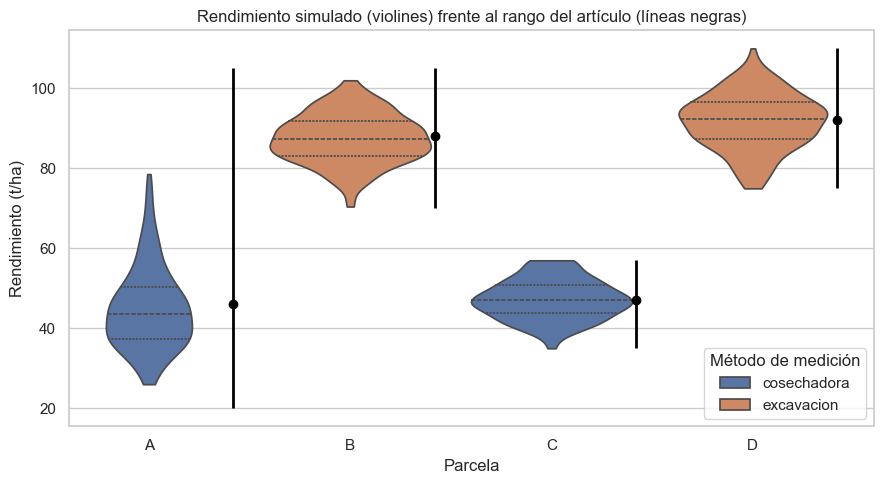

In [5]:
# Estadísticos del rendimiento simulado por parcela (combinación de referencia)
simulado = referencia.groupby("parcela")["rendimiento"].agg(
    media="mean", desv="std", minimo="min", maximo="max", asimetria="skew"
)

# Valores de referencia del artículo
articulo = (pd.DataFrame(config.PARCELAS_INFO).T[["media", "desv", "minimo", "maximo"]]
            .astype(float).add_suffix("_art"))

# Puntos recortados en los límites
def contar_en_limite(serie):
    info = config.PARCELAS_INFO[serie.name]
    return int(((serie <= info["minimo"]) | (serie >= info["maximo"])).sum())

comparacion = simulado.join(articulo)
comparacion["en_limite"] = referencia.groupby("parcela")["rendimiento"].apply(contar_en_limite)
display(comparacion.round(1))

# Gráfica: distribución simulada frente al rango del artículo
fig, ax = plt.subplots(figsize=(9, 5))
sns.violinplot(data=referencia, x="parcela", y="rendimiento", hue="metodo",
               inner="quartile", cut=0, ax=ax)
for i, p in enumerate(config.PARCELAS):
    info = config.PARCELAS_INFO[p]
    ax.vlines(i + 0.42, info["minimo"], info["maximo"], color="black", lw=2)
    ax.plot(i + 0.42, info["media"], "o", color="black")
ax.set(xlabel="Parcela", ylabel="Rendimiento (t/ha)",
       title="Rendimiento simulado (violines) frente al rango del artículo (líneas negras)")
ax.legend(title="Método de medición", loc="lower right")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "01_rendimiento_por_parcela.png", dpi=150)
plt.show()

**Resultado.**

| Parcela | Media sim. / art. | Desv. sim. / art. | Rango sim. | Rango art. | Puntos en el límite |
|---|---|---|---|---|---|
| A | 45,0 / 46 | 10,2 / 10,0 | 26,0–78,6 | 20–105 | 0 |
| B | 87,5 / 88 | 6,2 / 6,4 | 70,5–102,0 | 70–105 | 0 |
| C | 47,2 / 47 | 5,0 / 5,0 | 35,0–57,0 | 35–57 | 16 |
| D | 91,7 / 92 | 7,0 / 6,9 | 75,0–110,0 | 75–110 | 6 |

*Lo que se reproduce.* Las medias y las desviaciones estándar coinciden con los valores de referencia en las cuatro parcelas, con diferencias menores de 1 t/ha. La parcela A conserva su cola larga hacia valores altos (asimetría de 0,8), mientras B, C y D son aproximadamente simétricas.

*Lo que no se reproduce, y por qué.*

1. **El máximo de A (78,6 t/ha) queda lejos de los ~105 t/ha leídos en las figuras.** Con media 46 y desviación 10, alcanzar 105 exigiría una cola mucho más larga que la de una normal asimétrica. Ese valor extremo pudo deberse a pocos puntos atípicos del monitor de cosecha, o a la lectura aproximada de la figura.
2. **En C (16 puntos, 5 %) y D (6 puntos, 2 %) hay valores recortados en el límite.** Esos límites se leyeron de diagramas con ~90 puntos de prueba; con 300 puntos es esperable que algunos valores los superen. El recorte es pequeño, pero crea una ligera acumulación en los bordes.

Ambas diferencias se registran como limitaciones del generador. No afectan la media ni la dispersión, que son las que más influyen en el R².

### 4.2 Predictores por parcela

Se grafica la distribución de cada predictor (4 bandas y 4 índices) en cada parcela, y se calcula su coeficiente de variación (CV = desviación / media × 100). El CV permite comparar la variabilidad de variables con escalas distintas. Si la saturación del dosel actúa como se diseñó, los índices deberían variar mucho menos en las parcelas de alto rendimiento (B y D) que en las de bajo rendimiento (A y C), aunque el rendimiento varíe de forma parecida.

,rendimiento,azul,verde,rojo,nir,ndvi,gndvi,evi,savi
parcela,,,,,,,,,
A,22.8,13.2,8.0,15.2,7.1,11.1,5.8,14.4,12.1
B,7.1,7.3,4.8,9.6,4.0,2.4,1.6,4.1,3.3
C,10.5,9.3,7.0,10.3,5.4,6.1,3.3,7.8,6.6
D,7.7,7.2,4.7,9.5,3.7,2.2,1.4,3.8,2.9


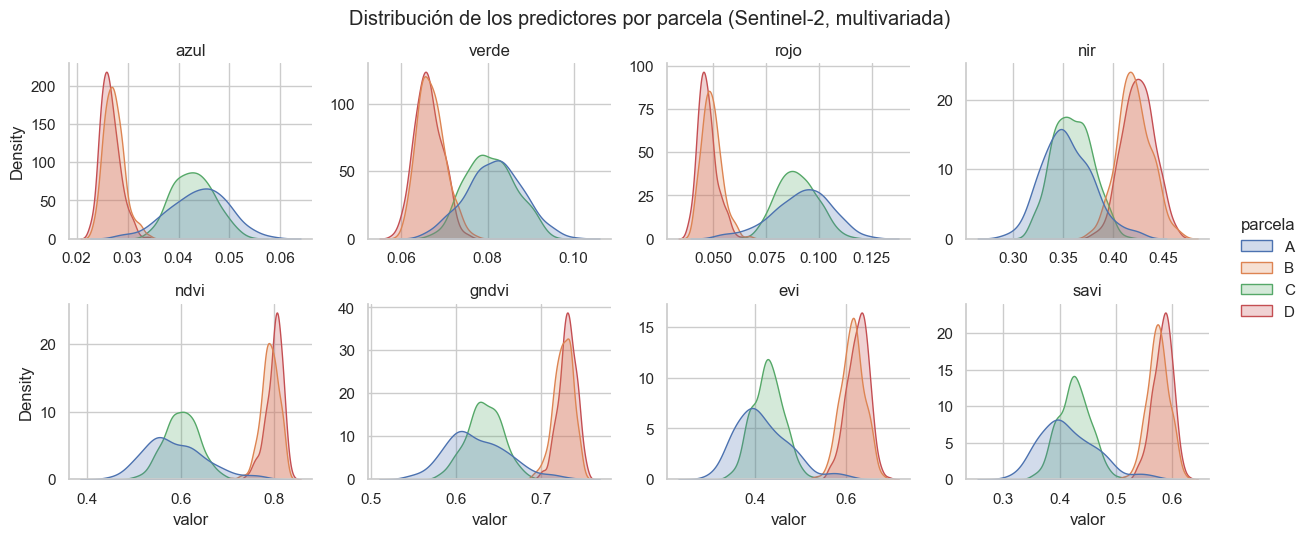

In [6]:
# Coeficiente de variación (%) de cada predictor y del rendimiento, por parcela
def cv(serie):
    return serie.std() / serie.mean() * 100

variabilidad = referencia.groupby("parcela")[[config.VARIABLE_RESPUESTA] + config.PREDICTORES].agg(cv)
display(variabilidad.round(1))

# Gráfica: distribución de cada predictor por parcela
largo = referencia.melt(id_vars="parcela", value_vars=config.PREDICTORES,
                        var_name="predictor", value_name="valor")
g = sns.displot(data=largo, x="valor", hue="parcela", col="predictor", col_wrap=4,
                kind="kde", fill=True, common_norm=False,
                facet_kws={"sharex": False, "sharey": False}, height=2.6, aspect=1.2)
g.set_titles("{col_name}")
g.figure.suptitle("Distribución de los predictores por parcela (Sentinel-2, multivariada)", y=1.03)
g.savefig(config.DIR_FIGURAS / "01_predictores_por_parcela.png", dpi=150)
plt.show()

**Resultado.**

*Dos grupos de parcelas.* En los ocho predictores, las parcelas forman dos grupos separados: A y C (rendimiento ~46 t/ha) y B y D (~90 t/ha). Las parcelas de alto rendimiento tienen menos rojo y azul (más absorción por la clorofila) y más NIR (más follaje). Con las cuatro parcelas juntas, esa separación produce correlaciones altas entre índices y rendimiento aunque dentro de cada parcela la relación sea más débil (hallazgo 2).

*La saturación, medida.* Coeficiente de variación (%) del rendimiento y del NDVI:

| Parcela | CV del rendimiento | CV del NDVI | Relación NDVI / rendimiento |
|---|---|---|---|
| A | 22,8 | 11,1 | 0,49 |
| C | 10,5 | 6,1 | 0,58 |
| B | 7,1 | 2,4 | 0,34 |
| D | 7,7 | 2,2 | 0,29 |

En B y D el rendimiento varía casi igual que en C (7–8 % frente a 10 %), pero el NDVI varía **menos de la mitad** (2,2–2,4 % frente a 6,1 %). Con el dosel casi cerrado, el índice comprime las diferencias de rendimiento: distingue peor entre puntos buenos y muy buenos. Es la saturación moderada que se incorporó al generador, y anticipa un R² más bajo en B y D.

*Índices que se saturan menos.* En B y D, el EVI (CV ~4 %) conserva más variación que el NDVI y el GNDVI (~2 %). Es coherente con la literatura: el EVI fue diseñado para saturarse menos en doseles densos.

## 5. Análisis para cada predictor frente al rendimiento

Se calcula la correlación de Pearson de cada predictor con el rendimiento, para cada sensor y cada estrategia de simulación, de dos maneras:

- **Global:** con las cuatro parcelas juntas, como probablemente se calculó la Figura 4 del artículo (hallazgo 2).
- **Dentro de cada parcela:** A, B, C y D por separado, que es la relación que realmente aprende cada modelo, porque el artículo modeló cada parcela de forma independiente.

La comparación con la Figura 4 solo es posible para los cuatro índices; el artículo no reporta correlaciones de las bandas.

,sensor,predictor,r_global,r_A,r_B,r_C,r_D,r_figura4
4,PlanetScope,ndvi,0.98,0.93,0.84,0.83,0.84,0.85
5,PlanetScope,gndvi,0.96,0.88,0.65,0.71,0.65,0.76
6,PlanetScope,evi,0.97,0.92,0.67,0.79,0.64,0.83
7,PlanetScope,savi,0.97,0.92,0.68,0.81,0.65,0.86
20,Sentinel-2,ndvi,0.98,0.93,0.87,0.86,0.86,0.90
21,Sentinel-2,gndvi,0.97,0.90,0.68,0.78,0.66,0.88
22,Sentinel-2,evi,0.98,0.93,0.71,0.85,0.66,0.89
23,Sentinel-2,savi,0.98,0.93,0.72,0.86,0.67,0.88


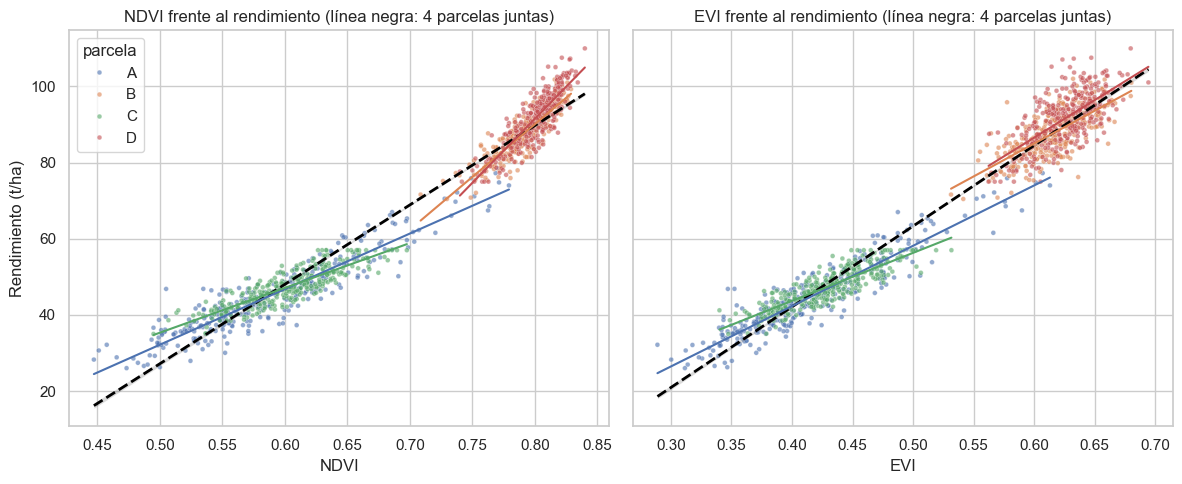

In [7]:
# Correlación de cada predictor con el rendimiento: global y dentro de cada parcela
muestreo = base[base["tipo_punto"] == "muestreo"]
filas = []
for (sensor, estrategia), datos in muestreo.groupby(["sensor", "estrategia"]):
    for predictor in config.PREDICTORES:
        fila = {
            "sensor": sensor,
            "estrategia": estrategia,
            "predictor": predictor,
            "r_global": datos[predictor].corr(datos["rendimiento"]),
        }
        for parcela, d in datos.groupby("parcela"):
            fila[f"r_{parcela}"] = d[predictor].corr(d["rendimiento"])
        fila["r_figura4"] = config.CORR_INDICE_RENDIMIENTO[sensor].get(predictor)
        filas.append(fila)
una_contra_una = pd.DataFrame(filas)

# Tabla resumida: índices, estrategia multivariada
indices_multi = una_contra_una[
    una_contra_una["predictor"].isin(config.INDICES)
    & (una_contra_una["estrategia"] == "multivariada")
]
display(indices_multi.drop(columns="estrategia").round(2))
una_contra_una.to_csv(config.DIR_RESULTADOS / "01_una_contra_una.csv", index=False)

# Gráfica: NDVI y EVI frente al rendimiento (Sentinel-2, multivariada)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
colores = dict(zip(config.PARCELAS, sns.color_palette()))
for ax, indice in zip(axes, ["ndvi", "evi"]):
    sns.scatterplot(data=referencia, x=indice, y="rendimiento", hue="parcela",
                    palette=colores, s=12, alpha=0.6, ax=ax)
    sns.regplot(data=referencia, x=indice, y="rendimiento", scatter=False, color="black",
                line_kws={"lw": 2, "ls": "--"}, ax=ax)
    for parcela, d in referencia.groupby("parcela"):
        sns.regplot(data=d, x=indice, y="rendimiento", scatter=False, ci=None,
                    color=colores[parcela], line_kws={"lw": 1.5}, ax=ax)
    ax.set(xlabel=indice.upper(), ylabel="Rendimiento (t/ha)",
           title=f"{indice.upper()} frente al rendimiento (línea negra: 4 parcelas juntas)")
axes[1].get_legend().remove()
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "01_una_contra_una.png", dpi=150)
plt.show()

**Resultado.** Correlación de cada índice con el rendimiento (estrategia multivariada):

| Sensor | Índice | Global | A | B | C | D | Figura 4 |
|---|---|---|---|---|---|---|---|
| Sentinel-2 | NDVI | 0,98 | 0,93 | 0,87 | 0,86 | 0,86 | 0,90 |
| Sentinel-2 | GNDVI | 0,97 | 0,90 | 0,68 | 0,78 | 0,66 | 0,88 |
| Sentinel-2 | EVI | 0,98 | 0,93 | 0,71 | 0,85 | 0,66 | 0,89 |
| Sentinel-2 | SAVI | 0,98 | 0,93 | 0,72 | 0,86 | 0,67 | 0,88 |
| PlanetScope | NDVI | 0,98 | 0,93 | 0,84 | 0,83 | 0,84 | 0,85 |

*1. La correlación global se infla por la diferencia entre parcelas.* Con las cuatro parcelas juntas, todos los índices llegan a 0,97–0,98, más que en cualquier parcela por separado. La gráfica lo muestra: la línea negra une dos nubes de puntos (A y C abajo, B y D arriba), y esa separación domina la correlación.

*2. Actualización del hallazgo 2.* Los valores de la Figura 4 (0,85–0,90) **no** coinciden con la correlación global simulada (0,98), sino que caen **dentro del rango de las correlaciones por parcela** (0,66–0,93). Esto matiza la hipótesis inicial: es posible que la Figura 4 se haya calculado dentro de una parcela, o promediando parcelas, y no con las cuatro juntas. En ese caso queda un punto pendiente: si el NDVI correlaciona ~0,90 con el rendimiento dentro de una parcela, una regresión lineal simple con el NDVI ya explicaría ~81 % de la variabilidad, más que los modelos del artículo. Se pondrá a prueba con una **línea base lineal** en la extensión.

*3. La saturación, vista en la gráfica.* En B y D (puntos naranjas y rojos), la pendiente es mucho más empinada: pequeñas diferencias de NDVI corresponden a grandes diferencias de rendimiento. El índice distingue peor entre puntos de alto rendimiento.

*4. El NDVI es el índice más robusto dentro de las parcelas de alto rendimiento.* En B y D conserva correlaciones de 0,84–0,87, mientras GNDVI, EVI y SAVI bajan a 0,66–0,72. El NDVI es un cociente que cancela el factor de iluminación y usa las dos bandas con más señal (rojo y NIR); el EVI incorpora el azul, más afectado por el ruido relativo, y el GNDVI usa el verde, que responde poco a la cobertura.

## 6. Análisis matriz de correlación completa

Se analizan las correlaciones de todos los predictores entre sí y con el rendimiento. Es la sección donde las dos estrategias de simulación se diferencian:

- **Univariada:** las bandas solo están conectadas entre sí a través del rendimiento (y de la cobertura que este determina).
- **Multivariada:** además, comparten el brillo del suelo (manchas húmedas o secas) y un factor de iluminación, que afectan a las cuatro bandas a la vez.

Primero se comparan las correlaciones entre índices con la Figura 4, calculadas de dos maneras: con las cuatro parcelas juntas (global) y dentro de cada parcela (promedio de las cuatro). Después se comparan las matrices completas de ambas estrategias en una misma parcela (C, Sentinel-2).

,sensor,par,global,dentro_parcela,figura4
0,Sentinel-2,GNDVI-EVI,0.981,0.797,0.80
1,Sentinel-2,NDVI-EVI,0.991,0.872,0.79
2,Sentinel-2,NDVI-GNDVI,0.991,0.889,0.78
3,Sentinel-2,SAVI-EVI,0.999,0.997,0.80
4,Sentinel-2,SAVI-GNDVI,0.984,0.812,0.77
5,Sentinel-2,SAVI-NDVI,0.992,0.877,0.80
6,PlanetScope,GNDVI-EVI,0.979,0.801,0.66
7,PlanetScope,NDVI-EVI,0.990,0.875,0.68
8,PlanetScope,NDVI-GNDVI,0.987,0.859,0.63
9,PlanetScope,SAVI-EVI,0.999,0.996,0.71


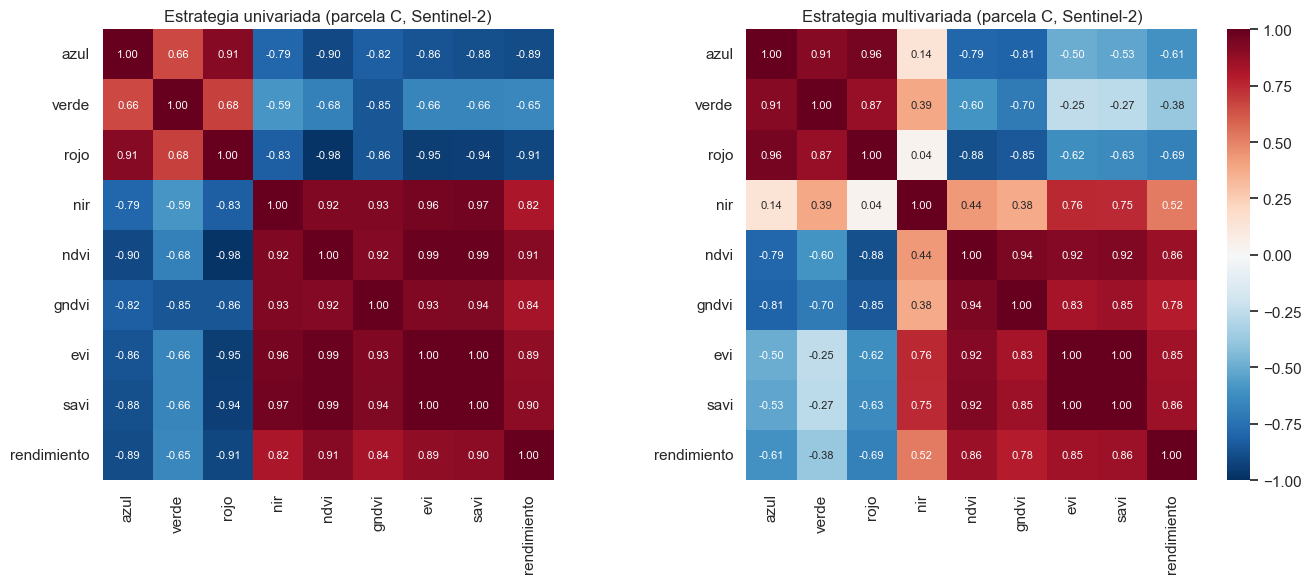

In [8]:
# 1. Correlaciones entre índices: global, dentro de cada parcela y Figura 4
figura4_entre_indices = {
    "Sentinel-2":  {("gndvi", "evi"): 0.80, ("ndvi", "evi"): 0.79, ("ndvi", "gndvi"): 0.78,
                    ("savi", "evi"): 0.80, ("savi", "gndvi"): 0.77, ("savi", "ndvi"): 0.80},
    "PlanetScope": {("gndvi", "evi"): 0.66, ("ndvi", "evi"): 0.68, ("ndvi", "gndvi"): 0.63,
                    ("savi", "evi"): 0.71, ("savi", "gndvi"): 0.65, ("savi", "ndvi"): 0.73},
}
filas = []
for sensor in config.SENSORES:
    datos = muestreo[(muestreo["sensor"] == sensor) & (muestreo["estrategia"] == "multivariada")]
    global_ = datos[config.INDICES].corr()
    dentro = sum(d[config.INDICES].corr() for _, d in datos.groupby("parcela")) / 4
    for (a, b), valor in figura4_entre_indices[sensor].items():
        filas.append({"sensor": sensor, "par": f"{a.upper()}-{b.upper()}",
                      "global": global_.loc[a, b], "dentro_parcela": dentro.loc[a, b],
                      "figura4": valor})
entre_indices = pd.DataFrame(filas)
display(entre_indices.round(3))
entre_indices.to_csv(config.DIR_RESULTADOS / "01_correlacion_entre_indices.csv", index=False)

# 2. Matrices completas por estrategia (parcela C, Sentinel-2)
variables = config.PREDICTORES + [config.VARIABLE_RESPUESTA]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, estrategia in zip(axes, config.ESTRATEGIAS):
    d = muestreo[(muestreo["sensor"] == "Sentinel-2") & (muestreo["estrategia"] == estrategia)
                 & (muestreo["parcela"] == "C")]
    sns.heatmap(d[variables].corr(), vmin=-1, vmax=1, cmap="RdBu_r", annot=True, fmt=".2f",
                annot_kws={"size": 8}, square=True, cbar=(estrategia == "multivariada"), ax=ax)
    ax.set_title(f"Estrategia {estrategia} (parcela C, Sentinel-2)")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "01_todas_contra_todas.png", dpi=150)
plt.show()

**Resultado.**

*1. Correlaciones entre índices frente a la Figura 4 (Sentinel-2, multivariada):*

| Par | Global | Dentro de parcela | Figura 4 |
|---|---|---|---|
| NDVI–SAVI | 0,99 | 0,88 | 0,80 |
| NDVI–GNDVI | 0,99 | 0,89 | 0,78 |
| NDVI–EVI | 0,99 | 0,87 | 0,79 |
| GNDVI–EVI | 0,98 | 0,80 | 0,80 |
| SAVI–GNDVI | 0,98 | 0,81 | 0,77 |
| SAVI–EVI | 1,00 | 1,00 | 0,80 |

Con las cuatro parcelas juntas, todos los pares superan 0,98. Dentro de cada parcela, en cambio, bajan a 0,80–0,89, muy cerca de los valores de la Figura 4. Esto refuerza la actualización del hallazgo 2 (sección 5): **la Figura 4 es más compatible con correlaciones calculadas dentro de las parcelas que con las cuatro juntas.**

*2. Matiz al hallazgo 3 (NDVI–SAVI).* En la prueba del generador (instrucción 24), NDVI y SAVI correlacionaban 0,998, pero allí la cobertura variaba en un rango amplio y no había factor de iluminación. Dentro de una parcela, con poca variación de cobertura, la correlación baja a ~0,88. La razón es que el NDVI es un cociente puro y cancela el factor de iluminación, mientras el SAVI (por su término L = 0,5) no lo cancela. Por lo tanto, **un 0,80 entre NDVI y SAVI es menos anómalo de lo que se supuso inicialmente**, si se calculó dentro de una parcela con variación de iluminación o de calibración entre píxeles.

*3. Lo que la simulación no reproduce.* SAVI y EVI correlacionan 1,00 en la simulación, frente a 0,80 en la Figura 4. En el generador ambos índices responden igual al rojo, al NIR y a la iluminación; en datos reales, el azul del EVI aporta variación atmosférica propia que el generador no incluye. Además, en la Figura 4 los seis pares tienen valores casi idénticos (0,77–0,80), algo poco habitual para índices con fórmulas tan distintas.

*4. Diferencia entre estrategias (parcela C).* En la univariada, el NIR correlaciona de forma negativa con las bandas visibles (−0,59 a −0,83): cuando hay más follaje, sube el NIR y bajan el rojo y el azul. En la multivariada, esa relación casi desaparece (0,04 a 0,39), porque el brillo del suelo sube **todas** las bandas a la vez y contrarresta el efecto del follaje. Por eso, en la multivariada las bandas sueltas correlacionan menos con el rendimiento (el rojo baja de −0,91 a −0,69), mientras los índices normalizados conservan correlaciones de 0,78–0,86. **Los índices son más robustos que las bandas cuando hay fuentes de variación compartidas**, y esa es la razón agronómica para preferirlos.

## 7. Estructura espacial e interpolación

### 7.1 Correlación según la distancia

Se mide cuánto se parecen los rendimientos de dos puntos según la distancia que los separa. Para cada parcela se estandariza el rendimiento y, para cada par de puntos, se multiplica el valor estandarizado de ambos; el promedio de ese producto en cada rango de distancia es la correlación a esa distancia.

Se calcula para el rendimiento **real** de las cuatro parcelas y para el rendimiento **interpolado** de B y D, y se compara con la curva teórica del generador:

correlación(d) = (1 − pepita) × exp(−3d / alcance), con alcance = 40 m y pepita = 0,20.

,parcela,version,5.0,15.0,25.0,35.0,50.0,70.0,100.0,160.0
0,A,real,0.61,0.29,0.24,0.15,0.02,-0.04,0.00,-0.02
1,B,real,0.66,0.27,0.18,0.13,0.03,0.04,0.01,-0.05
2,B,interpolado,0.75,0.79,0.72,0.73,0.50,0.24,0.10,-0.06
3,C,real,0.66,0.16,0.10,-0.02,0.03,-0.05,0.01,-0.01
4,D,real,0.38,0.22,0.21,0.07,0.01,0.00,-0.07,-0.02
5,D,interpolado,0.85,0.83,0.70,0.56,0.28,0.12,-0.04,-0.08


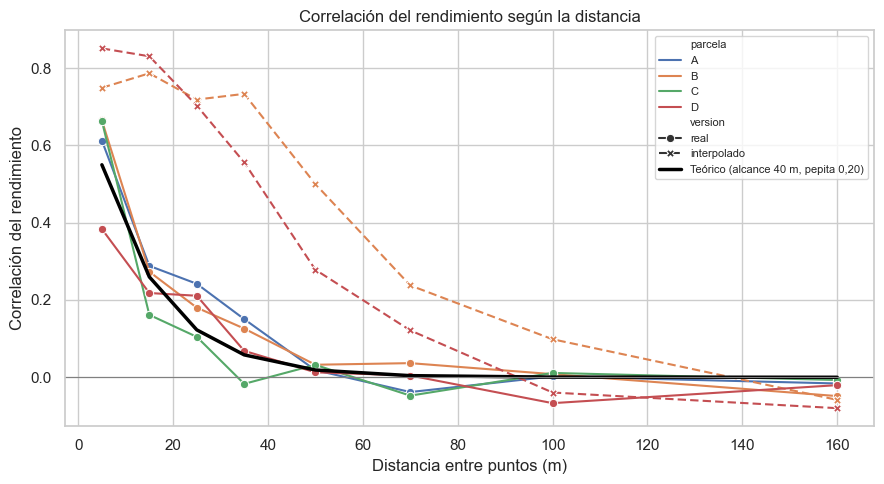

In [9]:
from scipy.spatial.distance import pdist

# Un registro por punto de muestreo (el rendimiento no depende del sensor ni de la estrategia)
puntos = base[(base["sensor"] == "Sentinel-2") & (base["estrategia"] == "univariada")
              & (base["tipo_punto"] == "muestreo")]

bordes = np.array([0, 10, 20, 30, 40, 60, 80, 120, 200])   # rangos de distancia (m)
centros = (bordes[:-1] + bordes[1:]) / 2

def correlograma(datos, columna):
    """Correlación promedio entre pares de puntos en cada rango de distancia."""
    xy = datos[["x", "y"]].to_numpy()
    v = datos[columna].to_numpy()
    z = (v - v.mean()) / v.std()
    distancias = pdist(xy)                   # distancias de todos los pares
    i, j = np.triu_indices(len(v), 1)        # los mismos pares, en el mismo orden
    producto = z[i] * z[j]
    return [producto[(distancias >= a) & (distancias < b)].mean()
            for a, b in zip(bordes[:-1], bordes[1:])]

filas = []
for parcela, d in puntos.groupby("parcela"):
    filas.append({"parcela": parcela, "version": "real",
                  **dict(zip(centros, correlograma(d, "rendimiento")))})
    if d["rendimiento_interpolado"].notna().all():
        filas.append({"parcela": parcela, "version": "interpolado",
                      **dict(zip(centros, correlograma(d, "rendimiento_interpolado")))})
correlogramas = pd.DataFrame(filas)
display(correlogramas.round(2))
correlogramas.to_csv(config.DIR_RESULTADOS / "01_correlograma.csv", index=False)

# Curva teórica del generador
a = config.AUTOCORRELACION
teorico = (1 - a["pepita"]) * np.exp(-3 * centros / a["alcance_m"])

# Gráfica
largo = correlogramas.melt(id_vars=["parcela", "version"], var_name="distancia",
                           value_name="correlacion")
largo["distancia"] = largo["distancia"].astype(float)
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=largo, x="distancia", y="correlacion", hue="parcela", style="version",
             markers=True, dashes={"real": "", "interpolado": (4, 2)}, ax=ax)
ax.plot(centros, teorico, color="black", lw=2.5, label="Teórico (alcance 40 m, pepita 0,20)")
ax.axhline(0, color="gray", lw=0.8)
ax.set(xlabel="Distancia entre puntos (m)", ylabel="Correlación del rendimiento",
       title="Correlación del rendimiento según la distancia")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "01_correlograma.png", dpi=150)
plt.show()

**Resultado.**

| Distancia | Teórico | Real (A, B, C, D) | Interpolado B | Interpolado D |
|---|---|---|---|---|
| 0–10 m | 0,55 | 0,38–0,66 | 0,75 | 0,85 |
| 10–20 m | 0,26 | 0,16–0,29 | 0,79 | 0,83 |
| 20–30 m | 0,12 | 0,10–0,24 | 0,72 | 0,70 |
| 30–40 m | 0,06 | −0,02–0,15 | 0,73 | 0,56 |
| 40–60 m | 0,02 | 0,01–0,03 | 0,50 | 0,28 |
| 60–80 m | 0,00 | −0,05–0,04 | 0,24 | 0,12 |

*1. El generador reproduce la estructura espacial definida.* En las cuatro parcelas, la correlación del rendimiento real sigue la curva teórica: alta entre vecinos cercanos, prácticamente nula a partir de los 40–50 m. Las diferencias en cada rango se deben a que cada parcela es una sola realización con 300 puntos.

*2. La interpolación crea una dependencia espacial artificial.* En B y D, el rendimiento interpolado mantiene correlaciones de 0,70–0,79 hasta los 30 m y de 0,28–0,50 entre 40 y 60 m, cuando el rendimiento real ya es independiente a esas distancias. Los puntos interpolados se parecen entre sí no porque el lote sea homogéneo, sino porque todos son promedios de las mismas 30 mediciones.

*3. Implicación para la fuga de información.* Con la partición aleatoria del artículo, cada punto de prueba tiene un vecino de entrenamiento a unos 13 m. A esa distancia, el rendimiento real correlaciona ~0,2–0,3, pero el interpolado ~0,8. En B y D, el conjunto de prueba es casi una copia del de entrenamiento: es la evidencia cuantitativa de los mecanismos 1 y 2 de la fuga por interpolación (pseudorreplicación y casi duplicados entre entrenamiento y prueba).

### 7.2 Rendimiento interpolado frente al real

En las parcelas de excavación (B y D), el artículo entrenó y evaluó los modelos con una superficie interpolada por IDW a partir de 30 mediciones manuales. Como en la simulación se conoce el rendimiento real de cada punto, se puede medir qué tan bien lo representa esa superficie:

- **Correlación** entre real e interpolado.
- **Desviación estándar** de ambos: cuánta variabilidad conserva la interpolación.
- **RMSE** de la interpolación (t/ha): error típico al usar el valor interpolado como si fuera el real.
- **R² de la interpolación**: fracción de la variabilidad real que captura la superficie interpolada.

,parcela,correlacion,desv_real,desv_interpolado,rmse_interpolacion,r2_interpolacion
0,B,0.24,6.17,3.68,6.47,-0.10
1,D,0.18,7.03,2.92,7.11,-0.03


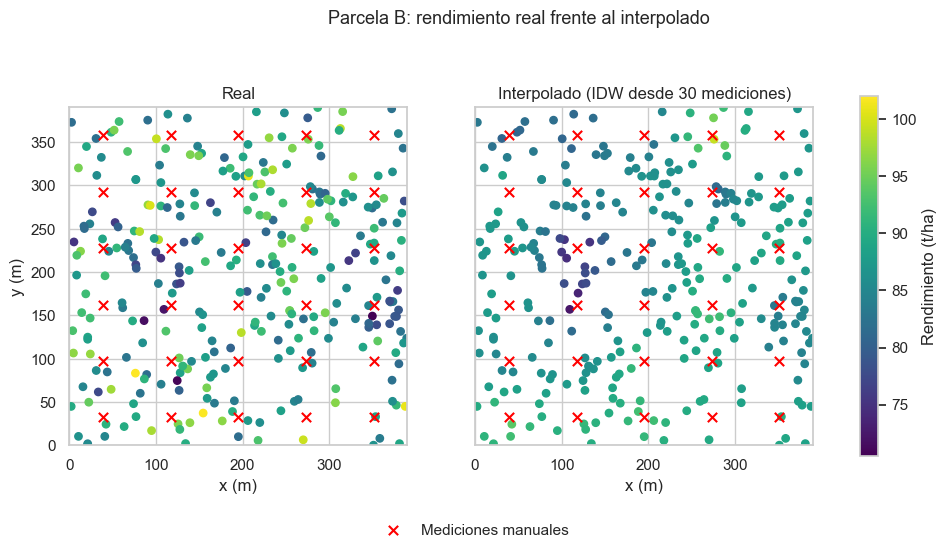

In [10]:
from src.evaluacion import calcular_metricas

# Calidad de la superficie interpolada frente al rendimiento real (B y D)
filas = []
for parcela in ["B", "D"]:
    d = puntos[puntos["parcela"] == parcela]
    metricas = calcular_metricas(d["rendimiento"], d["rendimiento_interpolado"])
    filas.append({
        "parcela": parcela,
        "correlacion": d["rendimiento"].corr(d["rendimiento_interpolado"]),
        "desv_real": d["rendimiento"].std(),
        "desv_interpolado": d["rendimiento_interpolado"].std(),
        "rmse_interpolacion": metricas["rmse"],
        "r2_interpolacion": metricas["r2"],
    })
calidad_interpolacion = pd.DataFrame(filas)
display(calidad_interpolacion.round(2))
calidad_interpolacion.to_csv(config.DIR_RESULTADOS / "01_calidad_interpolacion.csv", index=False)

# Mapas de la parcela B: real frente a interpolado
puntos_b = base[(base["sensor"] == "Sentinel-2") & (base["estrategia"] == "univariada")
                & (base["parcela"] == "B")]
muestreo_b = puntos_b[puntos_b["tipo_punto"] == "muestreo"]
medicion_b = puntos_b[puntos_b["tipo_punto"] == "medicion"]
escala = (muestreo_b["rendimiento"].min(), muestreo_b["rendimiento"].max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, columna, titulo in zip(axes, ["rendimiento", "rendimiento_interpolado"],
                               ["Real", "Interpolado (IDW desde 30 mediciones)"]):
    mapa = ax.scatter(muestreo_b["x"], muestreo_b["y"], c=muestreo_b[columna], cmap="viridis",
                      vmin=escala[0], vmax=escala[1], s=28)
    ax.scatter(medicion_b["x"], medicion_b["y"], marker="x", color="red", s=45,
               label="Mediciones manuales")
    ax.set(title=titulo, xlabel="x (m)", aspect="equal", xlim=(0, 390), ylim=(0, 390))
axes[0].set_ylabel("y (m)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", frameon=False)
fig.suptitle("Parcela B: rendimiento real frente al interpolado", fontsize=13)
fig.colorbar(mapa, ax=axes, label="Rendimiento (t/ha)", shrink=0.85)
fig.savefig(config.DIR_FIGURAS / "01_mapa_interpolacion_B.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultado.**

| Parcela | Correlación | Desv. real | Desv. interpolado | RMSE interpolación | R² interpolación |
|---|---|---|---|---|---|
| B | 0,24 | 6,2 | 3,7 | 6,5 | −0,10 |
| D | 0,18 | 7,0 | 2,9 | 7,1 | −0,03 |

*1. La interpolación borra entre el 40 % y el 60 % de la variabilidad del lote.* La desviación pasa de 6,2 a 3,7 t/ha en B y de 7,0 a 2,9 t/ha en D. En el mapa se ve: a la izquierda, las manchas del rendimiento real tienen colores contrastados; a la derecha, la superficie interpolada es un fondo casi uniforme con algunas zonas suavizadas alrededor de las mediciones.

*2. La superficie interpolada no predice mejor que el promedio.* Su RMSE (6,5 y 7,1 t/ha) es prácticamente igual a la desviación estándar del rendimiento real, y su R² frente al real es cercano a cero o negativo. Con manchas de 30 a 50 m y mediciones separadas 65 m, las 30 mediciones son demasiado escasas para reconstruir el lote.

*3. Consecuencia para el artículo.* En B y D, los modelos se entrenaron y evaluaron contra una superficie que, bajo estos supuestos, casi no contiene información del rendimiento real punto a punto. Un R² de 0,60–0,65 frente a esa superficie mide qué tan bien se reproduce la interpolación, no qué tan bien se predice el rendimiento (mecanismo 3 de la fuga por interpolación). El resultado depende del supuesto de manchas de 30 a 50 m; con manchas más grandes, la interpolación sería más fiel. Por eso se incluye la sensibilidad al alcance (medida R6) en la extensión.

## 8. Síntesis de la validación

### Lo que la simulación reproduce

| Característica | Referencia del artículo | Simulación | Sección |
|---|---|---|---|
| Media y desviación del rendimiento por parcela | Figuras 6, 7 y 10; Tablas 4 y 5 | Diferencias menores de 1 t/ha | 4.1 |
| Asimetría de la parcela A | Figuras 6 y 7 | Cola hacia valores altos (asimetría 0,8) | 4.1 |
| Dos grupos de parcelas (rendimiento bajo y alto) | Figuras 6 y 7 | Separados en los ocho predictores | 4.2 |
| Correlación índice–rendimiento | Figura 4: 0,76–0,90 | Dentro de parcela: 0,64–0,93 | 5 |
| Correlación entre índices | Figura 4: 0,63–0,80 | Dentro de parcela: 0,80–0,89 (salvo SAVI–EVI) | 6 |
| R² de prueba en A y C (calibración) | Tablas 4 y 5 | Diferencia media de 0,038 por parcela y sensor | Calibración |
| Estructura espacial definida (alcance 40 m, pepita 0,20) | Supuesto [S] | Correlograma real sigue la curva teórica | 7.1 |

### Lo que no reproduce (limitaciones del generador)

1. **Máximo de la parcela A:** 78,6 t/ha simulado frente a ~105 t/ha leído en las figuras.
2. **Recorte en los límites:** 5 % de los puntos en C y 2 % en D quedan en el borde del rango.
3. **SAVI–EVI:** correlación de 1,00 en la simulación frente a 0,80 en la Figura 4; el generador no incluye la variación atmosférica propia del azul.
4. **Orden de los modelos:** en la simulación, RF y GTB superan a CART; en el artículo, los tres rinden parecido. El ruido no puede cambiar ese orden.
5. **A y C con una misma curva de cobertura:** en la realidad son años distintos (2021 y 2022), con relaciones entre follaje y rendimiento que pueden diferir. Por eso la calibración deja A algo alta y C algo baja.

### Cambios en la lectura crítica del artículo

| Hallazgo | Antes | Después de la validación |
|---|---|---|
| **2** (correlaciones de la Figura 4) | Infladas por calcularse con las cuatro parcelas juntas | La correlación global simulada (0,98) supera a la Figura 4; sus valores son más compatibles con correlaciones **dentro** de las parcelas. Queda la pregunta de por qué los modelos no superan a una regresión simple con el NDVI (se probará en la extensión con una línea base lineal) |
| **3** (NDVI–SAVI de 0,80) | Incompatible con índices calculados sobre las mismas bandas | Dentro de una parcela, con variación de iluminación, baja a ~0,88: el 0,80 es menos anómalo de lo supuesto |
| **12** (nuevo) | — | Fuga por selección de hiperparámetros: se eligieron mirando el mismo conjunto con el que se reportan los resultados |
| **13** (nuevo) | — | R² de entrenamiento de 0,82–0,84 con árboles casi sin restricciones; en la simulación llega a 1,00 |
| **Interpolación** (nuevo) | Posible fuente de fuga | Cuantificada: en B y D, la superficie interpolada conserva solo el 40–60 % de la variabilidad real, mantiene correlaciones de 0,7–0,8 hasta 30 m y su R² frente al rendimiento real es ≈ 0 |

### Conclusión

La base simulada reproduce las características del artículo que más influyen en el desempeño de los modelos: niveles y dispersión del rendimiento, relación entre índices y rendimiento dentro de cada parcela, y R² de prueba en las parcelas de cosechadora. Sus limitaciones están identificadas y no afectan esas características. La base es adecuada para recrear el análisis del artículo (notebook 02) y para la extensión experimental sobre la fuga de información (notebook 03).